Define the functions for the metrics

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Global internal cache for processed prices to avoid repeated disk I/O
_PRICES_CACHE = None


def _load_internal_prices(
    prices_path: str = "entsoe_prices.csv",
    fx_path: str = "eur_nok_exchange_rates.csv",
) -> pd.DataFrame:
    """Internal helper to load electricity prices and dynamically convert EUR to NOK

    using official hour-by-hour exchange rates from Norges Bank.
    """
    global _PRICES_CACHE
    if _PRICES_CACHE is None:
        if not os.path.exists(prices_path):
            raise FileNotFoundError(
                f"Required price file '{prices_path}' not found."
            )

        pdf = pd.read_csv(prices_path)
        pdf["time"] = pd.to_datetime(pdf["time"], utc=True)

        if "spot_price_nok_mwh" not in pdf.columns:
            if os.path.exists(fx_path):
                fx_df = pd.read_csv(fx_path)
                fx_df["time"] = pd.to_datetime(fx_df["time"], utc=True)
                pdf = pd.merge(pdf, fx_df, on="time", how="left")
                pdf["eur_nok_rate"] = pdf["eur_nok_rate"].ffill().bfill()
                pdf["spot_price_nok_mwh"] = (
                    pdf["spot_price_eur_mwh"] * pdf["eur_nok_rate"]
                )
            else:
                pdf["spot_price_nok_mwh"] = pdf["spot_price_eur_mwh"] * 10.50

        _PRICES_CACHE = pdf[
            ["time", "location", "spot_price_nok_mwh"]
        ].copy()

    return _PRICES_CACHE


def compute_forecast_metrics(
    y_true: pd.Series | np.ndarray,
    y_pred: pd.Series | np.ndarray,
    timestamps: pd.Series | pd.DatetimeIndex | None = None,
    locations: pd.Series | np.ndarray | str | None = None,
    y_baseline: pd.Series | np.ndarray | None = None,
    contract_fee: float = 180_000.0,
    min_consumption_lag_hours: int = 168,
    pipeline_runtime_sec: float = 12.0,
    sla_max_runtime_sec: float = 1800.0,
    trust_tolerance_ratio: float = 0.15,
    prices_csv_path: str = "entsoe_prices.csv",
    fx_csv_path: str = "eur_nok_exchange_rates.csv",
) -> dict:
    """Black-box 4-Tier evaluation function for Electricity Consumption Forecasting."""
    # -------------------------------------------------------------------------
    # 0. Data Extraction & Timestamp Standardization
    # -------------------------------------------------------------------------
    if timestamps is None and isinstance(y_true, pd.Series):
        timestamps = y_true.index

    eval_df = pd.DataFrame(
        {
            "y_t": np.asarray(y_true, dtype=float),
            "y_p": np.asarray(y_pred, dtype=float),
        }
    )

    if y_baseline is not None:
        eval_df["y_b"] = np.asarray(y_baseline, dtype=float)

    if timestamps is not None:
        if isinstance(timestamps, pd.DatetimeIndex):
            eval_df["time"] = (
                timestamps.tz_convert("UTC")
                if timestamps.tz is not None
                else timestamps.tz_localize("UTC")
            )
        else:
            eval_df["time"] = pd.to_datetime(timestamps, utc=True)

    if locations is not None:
        if isinstance(locations, str):
            eval_df["location"] = locations
        else:
            eval_df["location"] = np.asarray(locations)

    cols_to_check = (
        ["y_t", "y_p", "y_b"] if y_baseline is not None else ["y_t", "y_p"]
    )
    eval_df = eval_df.dropna(subset=cols_to_check).copy()

    if len(eval_df) == 0:
        raise ValueError("No valid overlapping observations found.")

    # -------------------------------------------------------------------------
    # Black-box Price Loading & Merge
    # -------------------------------------------------------------------------
    if "time" in eval_df.columns and "location" in eval_df.columns:
        prices_df = _load_internal_prices(prices_csv_path, fx_csv_path)
        eval_df = pd.merge(
            eval_df, prices_df, on=["time", "location"], how="left"
        )
        eval_df["spot_price_nok_mwh"] = eval_df["spot_price_nok_mwh"].fillna(
            prices_df["spot_price_nok_mwh"].mean()
        )
        hourly_prices = eval_df["spot_price_nok_mwh"].values
    else:
        hourly_prices = np.full(len(eval_df), 1500.0)

    y_t = eval_df["y_t"].values
    y_p = eval_df["y_p"].values
    y_b = eval_df["y_b"].values if "y_b" in eval_df.columns else None

    # -------------------------------------------------------------------------
    # TIER 1: Technical & Statistical Modeling Metrics
    # -------------------------------------------------------------------------
    errors = y_p - y_t
    abs_errors = np.abs(errors)
    sum_actual = np.sum(y_t)

    mae = float(np.mean(abs_errors))
    rmse = float(np.sqrt(np.mean(errors**2)))
    wape = float((np.sum(abs_errors) / sum_actual) * 100) if sum_actual > 0 else np.nan
    nmbe = float((np.sum(errors) / sum_actual) * 100) if sum_actual > 0 else np.nan

    if y_b is not None:
        mae_base = float(np.mean(np.abs(y_b - y_t)))
        skill_score = (
            float((1.0 - (mae / mae_base)) * 100) if mae_base > 0 else 0.0
        )
    else:
        skill_score = 0.0

    # -------------------------------------------------------------------------
    # TIER 2: Business & Financial Value KPIs
    # -------------------------------------------------------------------------
    total_imbalance_mwh = float(np.sum(abs_errors) * 1.0)
    real_imbalance_cost_nok = float(np.sum(abs_errors * hourly_prices))

    if y_b is not None:
        base_imbalance_mwh = float(np.sum(np.abs(y_b - y_t)) * 1.0)
        avoided_mwh = float(base_imbalance_mwh - total_imbalance_mwh)
        imbalance_reduction_pct = (
            float((avoided_mwh / base_imbalance_mwh) * 100)
            if base_imbalance_mwh > 0
            else 0.0
        )

        base_imbalance_cost_nok = float(np.sum(np.abs(y_b - y_t) * hourly_prices))
        avoided_cost_nok = float(
            base_imbalance_cost_nok - real_imbalance_cost_nok
        )
    else:
        avoided_mwh = 0.0
        imbalance_reduction_pct = 0.0
        avoided_cost_nok = 0.0

    # -------------------------------------------------------------------------
    # TIER 3: Operational, Latency & MLOps SLA
    # -------------------------------------------------------------------------
    leakage_passed = min_consumption_lag_hours >= 120
    timeliness_passed = pipeline_runtime_sec <= sla_max_runtime_sec

    # -------------------------------------------------------------------------
    # TIER 4: Client Relationship & Trust
    # -------------------------------------------------------------------------
    # Net Financial ROI: (Avoided Penalties - Service Fee) / Service Fee * 100
    service_roi_pct = (
        float(((avoided_cost_nok - contract_fee) / contract_fee) * 100)
        if (contract_fee > 0 and y_b is not None)
        else np.nan
    )

    # Trust Score with epsilon guard against exact 0 MW consumption
    denom = np.where(y_t == 0, 1e-4, y_t)
    trust_reliability_pct = float(
        np.mean(abs_errors / denom <= trust_tolerance_ratio) * 100
    )
    p95_imbalance_mw = float(np.percentile(abs_errors, 95))

    return {
        "info": {
            "mae": "T1: MAE [MW]",
            "rmse": "T1: RMSE [MW]",
            "wape": "T1: WAPE [%]",
            "nmbe": "T1: NMBE [%]",
            "outperformance": "T1: Outperformance [%]",
            "total_imbalance": "T2: Total Imbalance [MWh]",
            "avoided_imbalance": "T2: Avoided Imbalance [MWh]",
            "imbalance_cost": "T2: Imbalance Cost [NOK]",
            "avoided_cost": "T2: Avoided Cost [NOK]",
            "leakage": "T3: Leakage (>=120h)",
            "timeliness": "T3: Timeliness (SLA)",
            "roi": "T4: Net Service ROI [%]",
            "trust": f"T4: Trust (Err <{trust_tolerance_ratio * 100:.0f}%) [%]",
            "p95_imbalance": "T4: P95 Imbalance [MW]",
        },
        # Tier 1
        "mae": mae,
        "rmse": rmse,
        "wape": wape,
        "nmbe": nmbe,
        "outperformance": skill_score,
        # Tier 2 (numeric floats so they remain mathematically plottable & summable)
        "total_imbalance": total_imbalance_mwh,
        "avoided_imbalance": avoided_mwh,
        "imbalance_cost": real_imbalance_cost_nok,
        "avoided_cost": avoided_cost_nok,
        # Tier 3
        "leakage": "PASS" if leakage_passed else "FAIL (Data Leakage)",
        "timeliness": "PASS" if timeliness_passed else "FAIL (Late)",
        # Tier 4
        "roi": service_roi_pct,
        "trust": trust_reliability_pct,
        "p95_imbalance": p95_imbalance_mw,
    }


def evaluate_forecast_by_location(
    data: pd.DataFrame,
    pred_col: str,
    target_col: str = "consumption",
    baseline_col: str | None = "baseline_pred_7d",
    location_col: str = "location",
    retailer_daily_fee_total: float = 10_000.0,
    min_lag_hours: int = 120,
) -> pd.DataFrame:
    """Helper to evaluate across all locations using rational total daily fee allocation."""
    results = []

    time_series = (
        data.index if isinstance(data.index, pd.DatetimeIndex) else data["time"]
    )
    time_series_utc = pd.to_datetime(time_series, utc=True)
    full_days = (time_series_utc.max() - time_series_utc.min()).days + 1

    # Total service contract fee paid by the retailer over the evaluation window
    total_retailer_contract_fee = retailer_daily_fee_total * full_days

    # Allocate the retailer fee across price areas proportionally to their consumption volume
    city_consumption = data.groupby(location_col, observed=False)[
        target_col
    ].sum()
    total_portfolio_consumption = city_consumption.sum()
    city_weights = (
        city_consumption / total_portfolio_consumption
        if total_portfolio_consumption > 0
        else 1 / len(city_consumption)
    )

    # 1. Per-city evaluation
    for loc, group in data.groupby(location_col, observed=False):
        g_time = (
            group.index
            if isinstance(group.index, pd.DatetimeIndex)
            else group["time"]
        )
        allocated_city_fee = (
            total_retailer_contract_fee * city_weights.get(loc, 1 / len(city_weights))
        )

        metrics = compute_forecast_metrics(
            y_true=group[target_col],
            y_pred=group[pred_col],
            timestamps=g_time,
            locations=loc,
            y_baseline=group[baseline_col] if baseline_col else None,
            contract_fee=allocated_city_fee,
            min_consumption_lag_hours=min_lag_hours,
        )
        metrics[location_col] = str(loc)
        results.append(metrics)

    # 2. Overall portfolio evaluation (Full retailer contract fee)
    overall_metrics = compute_forecast_metrics(
        y_true=data[target_col],
        y_pred=data[pred_col],
        timestamps=time_series,
        locations=data[location_col],
        y_baseline=data[baseline_col] if baseline_col else None,
        contract_fee=total_retailer_contract_fee,
        min_consumption_lag_hours=min_lag_hours,
    )
    overall_metrics[location_col] = "OVERALL"
    results.append(overall_metrics)

    return pd.DataFrame(results).set_index(location_col)

Note: Outperformance, Avoided Imbalance, Avoided Cost and ROI are all metrics that we have to compare with models other than the baseline, since they are calculated w.r.t. the baseline.

Some tricky KPIs:
- **Return on Investment (ROI)**: is calculated based on avoided costs w.r.t the baseline over the contract fee. A ROI >= 0 means it is not inconvenient to be Aneo's client; to satisfy the rule "fee <= (1/3)*savings" we should have ROI >= 2.
- **Trust Reliability**: Percentage of hours where the relative error stays within a commercial threshold (e.g., <15%). Higher is better for operational confidence.
- **P95 Imbalance [MW]**: 95th percentile worst-case error. Quantifies tail risk. Lower is better (rule of thumb: P95 < 2.5 * MAE).


---
Load the consumption dataset, parse timestamps as UTC and drop the first 32 hours of Helsinki containing zero-consumption sensor commissioning artifacts identified during EDA.

In [69]:
import seaborn as sns

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

# 1. Load dataset with UTC timestamps
df = pd.read_csv("consumption_temp.csv")
df["time"] = pd.to_datetime(df["time"], utc=True)
df = df.drop_duplicates(["time", "location"]).sort_values(["location", "time"]).reset_index(drop=True)

# 2. Trim unmetered commissioning zero artifact for Helsinki (Helsingfors)
initial_len = len(df)
helsinki_startup_mask = (df["location"] == "helsingfors") & (df["time"] < "2022-07-16 05:00:00+00:00")
df = df[~helsinki_startup_mask].reset_index(drop=True)

print(f"Dataset loaded. Rows dropped for Helsinki: {initial_len - len(df)} (expected: 32)")
print(f"Temporal span: {df['time'].min()} to {df['time'].max()}")
print(f"Monitored locations: {df['location'].unique().tolist()}")

Dataset loaded. Rows dropped for Helsinki: 32 (expected: 32)
Temporal span: 2022-04-07 21:00:00+00:00 to 2023-04-02 21:00:00+00:00
Monitored locations: ['bergen', 'helsingfors', 'oslo', 'stavanger', 'tromsø', 'trondheim']


Create the non-learning baseline ($y_{t-168}$, same hour last week) respecting the 120h+ delay constraint and extract the final 90-day out-of-time test window.

In [70]:
# 1. Compute 7-day Naive Baseline (lag 168h, safe from the >=120h latency constraint)
df = df.sort_values(["location", "time"]).reset_index(drop=True)
df["pred_baseline"] = df.groupby("location")["consumption"].shift(168)

# 2. Set chronological test split (final 90 days, matching the ML models)
TEST_DAYS = 90
cut_time = df["time"].max() - pd.Timedelta(days=TEST_DAYS)

# Extract baseline test evaluation slice
test_baseline = df[df["time"] > cut_time][["time", "location", "consumption", "pred_baseline"]].dropna()

print(f"Test cutoff date: {cut_time}")
print(f"Test records for baseline: {len(test_baseline)}")

Test cutoff date: 2023-01-02 21:00:00+00:00
Test records for baseline: 12960


Read pre-computed predictions from `ridge_test_predictions.csv` and `lgbm_test_predictions.csv`, merging them into an aligned test evaluation table with residual errors.

In [71]:
# 1. Load pre-computed test predictions
df_ridge = pd.read_csv("ridge_test_predictions.csv")
df_ridge["time"] = pd.to_datetime(df_ridge["time"], utc=True)

df_lgbm = pd.read_csv("lgbm_test_predictions.csv")
df_lgbm["time"] = pd.to_datetime(df_lgbm["time"], utc=True)

# 2. Merge baseline, Ridge, and LightGBM on [time, location]
df_eval = test_baseline.merge(
    df_ridge[["time", "location", "pred"]].rename(columns={"pred": "pred_ridge"}),
    on=["time", "location"],
    how="inner"
).merge(
    df_lgbm[["time", "location", "pred"]].rename(columns={"pred": "pred_lgbm"}),
    on=["time", "location"],
    how="inner"
)

# Compute point errors (prediction - ground truth)
df_eval["err_baseline"] = df_eval["pred_baseline"] - df_eval["consumption"]
df_eval["err_ridge"] = df_eval["pred_ridge"] - df_eval["consumption"]
df_eval["err_lgbm"] = df_eval["pred_lgbm"] - df_eval["consumption"]

print(f"Alignment complete: {len(df_eval)} matching hourly observations.")
df_eval.head()

Alignment complete: 12960 matching hourly observations.


,time,location,consumption,pred_baseline,pred_ridge,pred_lgbm,err_baseline,err_ridge,err_lgbm
0,2023-01-02 22:00:00+00:00,bergen,4.073836,3.302431,3.716234,4.058371,-0.771405,-0.357601,-0.015465
1,2023-01-02 23:00:00+00:00,bergen,3.841709,3.210991,3.592140,3.956101,-0.630718,-0.249568,0.114393
2,2023-01-03 00:00:00+00:00,bergen,3.673666,3.034290,3.390979,3.691191,-0.639376,-0.282687,0.017526
3,2023-01-03 01:00:00+00:00,bergen,3.558836,2.928382,3.249691,3.481959,-0.630454,-0.309144,-0.076876
4,2023-01-03 02:00:00+00:00,bergen,3.553401,2.809213,3.146215,3.306408,-0.744188,-0.407185,-0.246992


Run `evaluate_forecast_by_location` across all three models and outputs the complete 4-Tier metric comparison table (statistical, imbalance cost, SLA and business value).

In [72]:
# 1. Evaluate Baseline
metrics_base = evaluate_forecast_by_location(
    data=df_eval,
    pred_col="pred_baseline",
    baseline_col=None
)

# 2. Evaluate RidgeCV against Baseline
metrics_ridge = evaluate_forecast_by_location(
    data=df_eval,
    pred_col="pred_ridge",
    baseline_col="pred_baseline"
)

# 3. Evaluate LightGBM against Baseline
metrics_lgbm = evaluate_forecast_by_location(
    data=df_eval,
    pred_col="pred_lgbm",
    baseline_col="pred_baseline"
)

# 4. Overall portfolio summary table
summary_overall = pd.DataFrame({
    "Baseline (Lag 168h)": metrics_base.loc["OVERALL"],
    "RidgeCV (Linear)": metrics_ridge.loc["OVERALL"],
    "LightGBM (GBDT)": metrics_lgbm.loc["OVERALL"]
})

# inject information labels for clarity and remove the first row which contains the 'info' mapping
summary_overall.index = summary_overall.index.map(metrics_base.loc["OVERALL"]["info"])
summary_overall = summary_overall.drop(summary_overall.index[0], axis=0)

print("=== PORTFOLIO-LEVEL 4-TIER EVALUATION (90-DAY TEST SET) ===")
summary_overall

=== PORTFOLIO-LEVEL 4-TIER EVALUATION (90-DAY TEST SET) ===


,Baseline (Lag 168h),RidgeCV (Linear),LightGBM (GBDT)
T1: MAE [MW],0.525389,0.28675,0.277775
T1: RMSE [MW],0.867439,0.458702,0.427186
T1: WAPE [%],9.479564,5.173805,5.011876
T1: NMBE [%],0.870168,-2.26165,1.44482
T1: Outperformance [%],0.0,45.421493,47.129683
T2: Total Imbalance [MWh],6809.042586,3716.273759,3599.962383
T2: Avoided Imbalance [MWh],0.0,3092.768827,3209.080203
T2: Imbalance Cost [NOK],7215769.631934,3923435.533085,3765260.369001
T2: Avoided Cost [NOK],0.0,3292334.098849,3450509.262933
T3: Leakage (>=120h),PASS,PASS,PASS


More information city by city

In [73]:
cities = [c for c in metrics_lgbm.index if c != "OVERALL"]
# -------------------------------------------------------------
# TIER 1: Technical & Accuracy (MAE, RMSE, WAPE, Outperformance)
# -------------------------------------------------------------
tier1_city_df = pd.DataFrame({
    "Base MAE": metrics_base.loc[cities, "mae"],
    "Ridge MAE": metrics_ridge.loc[cities, "mae"],
    "LGBM MAE": metrics_lgbm.loc[cities, "mae"],
    "Base WAPE [%]": metrics_base.loc[cities, "wape"],
    "Ridge WAPE [%]": metrics_ridge.loc[cities, "wape"],
    "LGBM WAPE [%]": metrics_lgbm.loc[cities, "wape"],
    "Ridge Outperf. [%]": metrics_ridge.loc[cities, "outperformance"],
    "LGBM Outperf. [%]": metrics_lgbm.loc[cities, "outperformance"]
}).round(2)
print("=== TIER 1: ACCURACY & TECHNICAL METRICS BY CITY ===")
display(tier1_city_df)
# -------------------------------------------------------------
# TIER 2: Business & Financial Impact (Imbalance & Avoided Cost)
# -------------------------------------------------------------
tier2_city_df = pd.DataFrame({
    "Base Cost [NOK]": metrics_base.loc[cities, "imbalance_cost"],
    "Ridge Cost [NOK]": metrics_ridge.loc[cities, "imbalance_cost"],
    "LGBM Cost [NOK]": metrics_lgbm.loc[cities, "imbalance_cost"],
    "Ridge Avoided [NOK]": metrics_ridge.loc[cities, "avoided_cost"],
    "LGBM Avoided [NOK]": metrics_lgbm.loc[cities, "avoided_cost"]
}).round(0)
print("\n=== TIER 2: FINANCIAL VALUE & AVOIDED COSTS BY CITY ===")
display(tier2_city_df)
# -------------------------------------------------------------
# TIER 4: Client Trust & Risk (Trust %, P95 Imbalance, ROI)
# -------------------------------------------------------------
tier4_city_df = pd.DataFrame({
    "Base Trust (<15%) [%]": metrics_base.loc[cities, "trust"],
    "Ridge Trust (<15%) [%]": metrics_ridge.loc[cities, "trust"],
    "LGBM Trust (<15%) [%]": metrics_lgbm.loc[cities, "trust"],
    "Base P95 [MW]": metrics_base.loc[cities, "p95_imbalance"],
    "Ridge P95 [MW]": metrics_ridge.loc[cities, "p95_imbalance"],
    "LGBM P95 [MW]": metrics_lgbm.loc[cities, "p95_imbalance"],
    "Ridge ROI [x]": metrics_ridge.loc[cities, "roi"],
    "LGBM ROI [x]": metrics_lgbm.loc[cities, "roi"]
}).round(2)
print("\n=== TIER 4: TRUST, RISK (P95) & ROI BY CITY ===")
display(tier4_city_df)


=== TIER 1: ACCURACY & TECHNICAL METRICS BY CITY ===


,Base MAE,Ridge MAE,LGBM MAE,Base WAPE [%],Ridge WAPE [%],LGBM WAPE [%],Ridge Outperf. [%],LGBM Outperf. [%]
location,,,,,,,,
bergen,0.36,0.19,0.20,11.24,5.95,6.20,47.11,44.83
helsingfors,0.13,0.14,0.14,2.01,2.23,2.20,-11.20,-9.66
oslo,1.43,0.75,0.67,11.64,6.13,5.42,47.31,53.46
stavanger,0.61,0.31,0.34,10.59,5.47,6.00,48.32,43.35
tromsø,0.18,0.10,0.10,9.40,4.94,5.12,47.42,45.54
trondheim,0.44,0.22,0.22,12.10,6.09,5.93,49.66,50.96



=== TIER 2: FINANCIAL VALUE & AVOIDED COSTS BY CITY ===


,Base Cost [NOK],Ridge Cost [NOK],LGBM Cost [NOK],Ridge Avoided [NOK],LGBM Avoided [NOK]
location,,,,,
bergen,937885.0,494937.0,525881.0,442947.0,412004.0
helsingfors,280549.0,311982.0,307651.0,-31434.0,-27102.0
oslo,3114914.0,1641227.0,1449816.0,1473687.0,1665098.0
stavanger,1316636.0,680424.0,745833.0,636212.0,570803.0
tromsø,397913.0,209235.0,216723.0,188678.0,181191.0
trondheim,956298.0,481437.0,468986.0,474860.0,487312.0



=== TIER 4: TRUST, RISK (P95) & ROI BY CITY ===


,Base Trust (<15%) [%],Ridge Trust (<15%) [%],LGBM Trust (<15%) [%],Base P95 [MW],Ridge P95 [MW],LGBM P95 [MW],Ridge ROI [x],LGBM ROI [x]
location,,,,,,,,
bergen,70.74,95.14,93.29,0.82,0.47,0.50,38.05,28.40
helsingfors,98.52,98.98,99.12,0.54,0.35,0.39,-104.94,-104.26
oslo,69.26,95.93,94.81,3.74,1.89,1.67,21.02,36.74
stavanger,71.48,95.00,93.52,1.44,0.90,0.85,12.50,0.94
tromsø,79.91,98.38,97.96,0.45,0.23,0.25,-2.02,-5.90
trondheim,67.27,97.78,93.52,1.00,0.50,0.55,32.07,35.53


Generate the core figures for Task 3: a 14-day sample time series plot, the diurnal error curve (MAE by hour of day) and a location comparison bar chart.

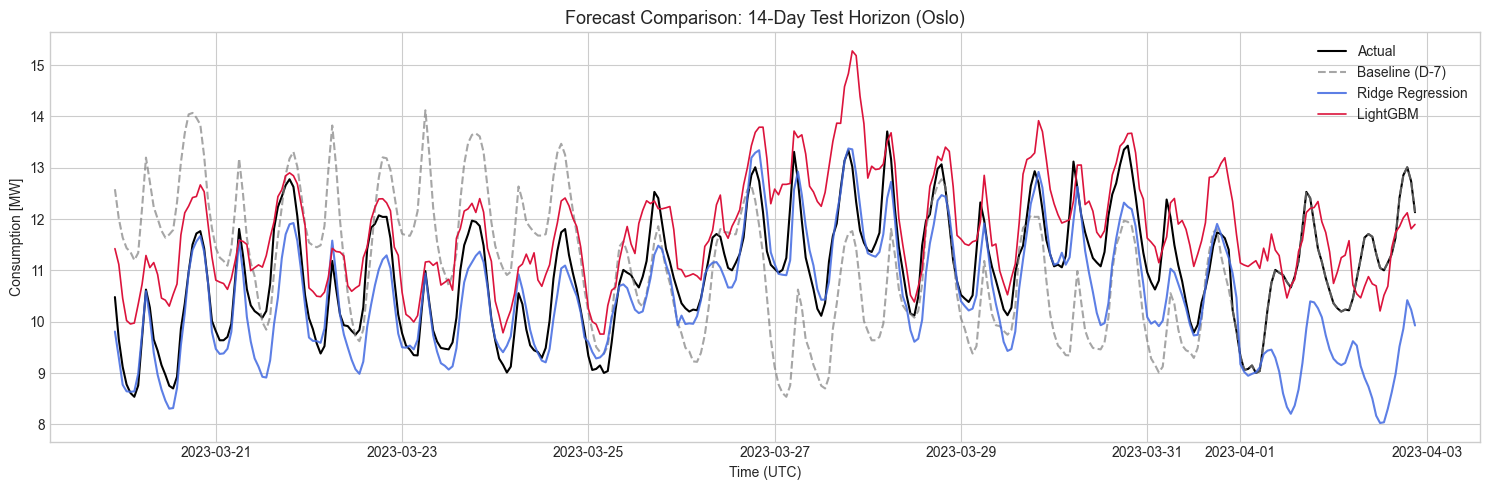

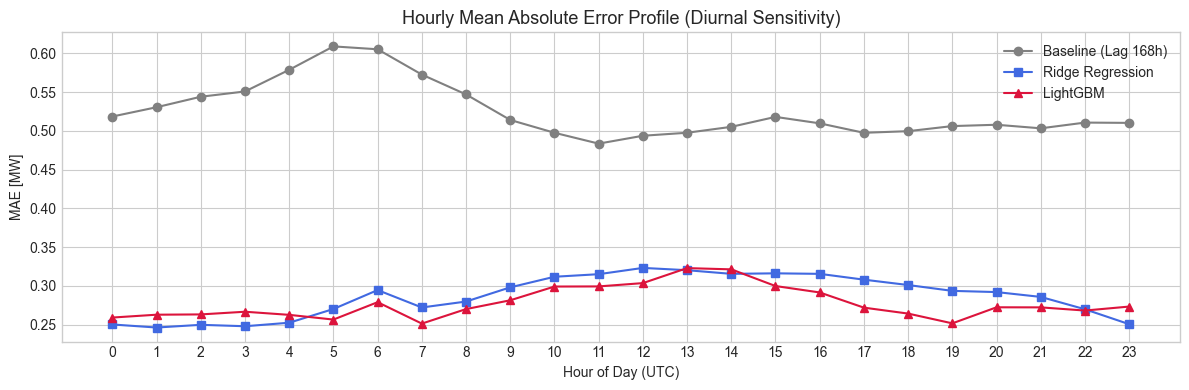

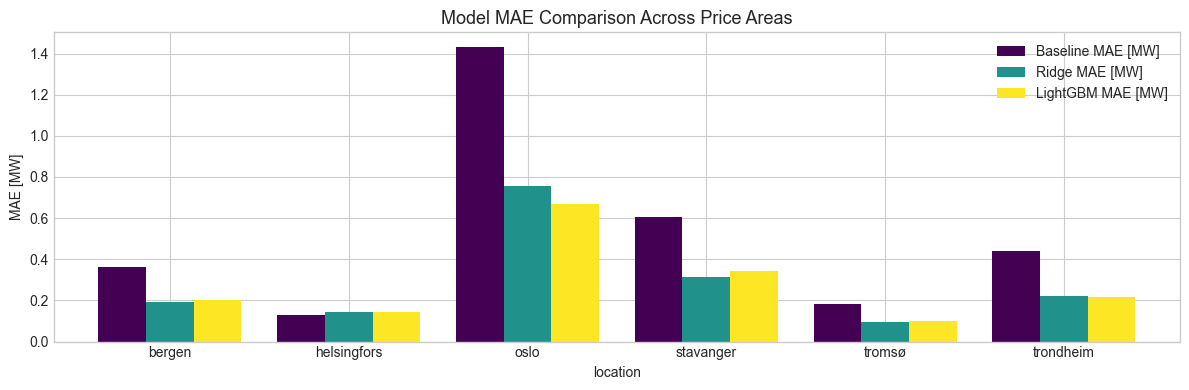

In [74]:
# Figure 1: Actual vs Predictions on a 14-day sample interval (Oslo)
sample_city = "oslo"
sample_slice = df_eval[df_eval["location"] == sample_city].tail(24 * 14)

plt.figure(figsize=(15, 5))
plt.plot(sample_slice["time"], sample_slice["consumption"], label="Actual", color="black", linewidth=1.5)
plt.plot(sample_slice["time"], sample_slice["pred_baseline"], label="Baseline (D-7)", color="gray", linestyle="--", alpha=0.7)
plt.plot(sample_slice["time"], sample_slice["pred_ridge"], label="Ridge Regression", color="royalblue", alpha=0.85)
plt.plot(sample_slice["time"], sample_slice["pred_lgbm"], label="LightGBM", color="crimson", linewidth=1.2)
plt.title(f"Forecast Comparison: 14-Day Test Horizon ({sample_city.capitalize()})", fontsize=13)
plt.xlabel("Time (UTC)")
plt.ylabel("Consumption [MW]")
plt.legend()
plt.tight_layout()
plt.show()

# Figure 2: Mean Absolute Error by Hour of the Day (0 to 23 UTC)
df_eval["hour"] = df_eval["time"].dt.hour
hourly_mae = pd.DataFrame({
    "Baseline": df_eval.groupby("hour")["err_baseline"].apply(lambda e: e.abs().mean()),
    "Ridge": df_eval.groupby("hour")["err_ridge"].apply(lambda e: e.abs().mean()),
    "LightGBM": df_eval.groupby("hour")["err_lgbm"].apply(lambda e: e.abs().mean())
})

plt.figure(figsize=(12, 4))
plt.plot(hourly_mae.index, hourly_mae["Baseline"], marker="o", label="Baseline (Lag 168h)", color="gray")
plt.plot(hourly_mae.index, hourly_mae["Ridge"], marker="s", label="Ridge Regression", color="royalblue")
plt.plot(hourly_mae.index, hourly_mae["LightGBM"], marker="^", label="LightGBM", color="crimson")
plt.xticks(range(0, 24))
plt.title("Hourly Mean Absolute Error Profile (Diurnal Sensitivity)", fontsize=13)
plt.xlabel("Hour of Day (UTC)")
plt.ylabel("MAE [MW]")
plt.legend()
plt.tight_layout()
plt.show()

# Figure 3: Location MAE Comparison Bar Chart
city_mae = pd.DataFrame({
    "Baseline MAE [MW]": metrics_base.loc[cities, "mae"],
    "Ridge MAE [MW]": metrics_ridge.loc[cities, "mae"],
    "LightGBM MAE [MW]": metrics_lgbm.loc[cities, "mae"]
})
city_mae.plot(kind="bar", figsize=(12, 4), colormap="viridis", width=0.8)
plt.title("Model MAE Comparison Across Price Areas", fontsize=13)
plt.ylabel("MAE [MW]")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Tracks total portfolio financial savings accumulated day by day across the 90-day test set, linking technical accuracy directly to financial value for Task 4.

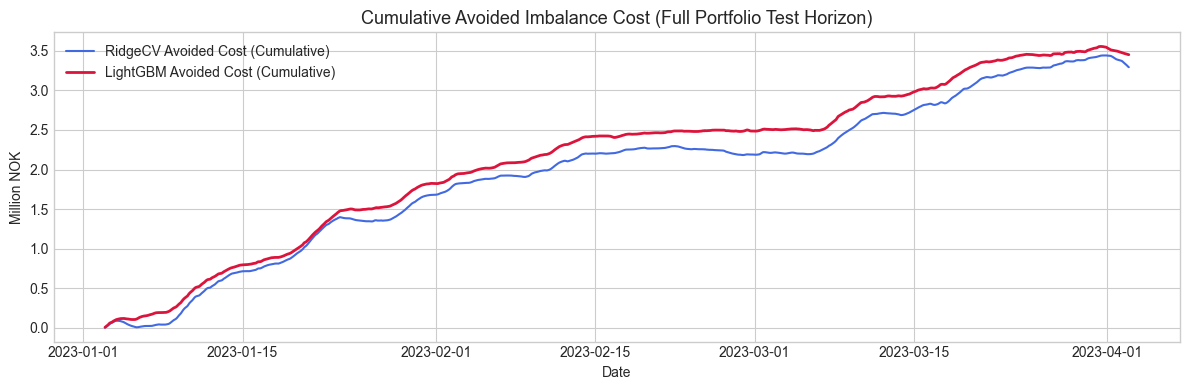

In [ ]:
# 1. Merge hourly spot settlement prices
prices = _load_internal_prices()
eval_with_price = df_eval.merge(prices, on=["time", "location"], how="left")
eval_with_price["spot_price_nok_mwh"] = eval_with_price["spot_price_nok_mwh"].fillna(
    eval_with_price["spot_price_nok_mwh"].mean()
)

# 2. Compute hourly imbalance penalty costs per observation
eval_with_price["cost_base"] = eval_with_price["err_baseline"].abs() * eval_with_price["spot_price_nok_mwh"]
eval_with_price["cost_ridge"] = eval_with_price["err_ridge"].abs() * eval_with_price["spot_price_nok_mwh"]
eval_with_price["cost_lgbm"] = eval_with_price["err_lgbm"].abs() * eval_with_price["spot_price_nok_mwh"]

# 3. Aggregate across all locations to portfolio level and calculate cumulative savings
portfolio_hourly = eval_with_price.groupby("time")[["cost_base", "cost_ridge", "cost_lgbm"]].sum()
cum_savings_ridge = (portfolio_hourly["cost_base"] - portfolio_hourly["cost_ridge"]).cumsum()
cum_savings_lgbm = (portfolio_hourly["cost_base"] - portfolio_hourly["cost_lgbm"]).cumsum()

# 4. Plot cumulative financial value
plt.figure(figsize=(12, 4))
plt.plot(cum_savings_ridge.index, cum_savings_ridge / 1e6, label="RidgeCV Avoided Cost (Cumulative)", color="royalblue")
plt.plot(cum_savings_lgbm.index, cum_savings_lgbm / 1e6, label="LightGBM Avoided Cost (Cumulative)", color="crimson", linewidth=2)
plt.title("Cumulative Avoided Imbalance Cost (Full Portfolio Test Horizon)", fontsize=13)
plt.xlabel("Date")
plt.ylabel("Million NOK")
plt.legend()
plt.tight_layout()
plt.show()